# KQC Stripes — ground-grid / lithography stripes (Quantcore PDK rebuild)

**What the chip is.** KQCircuits' `chips/stripes.py` (class `Stripes`, default parameters, chip name "CTest";
© IQM Finland Oy, GPL-3.0, <https://github.com/iqm-finland/KQCircuits>; local copy
`other-libs/KQCircuits-main/.../kqcircuits/chips/stripes.py`; spec `docs/designs/kqc/test_chips.md`, one
notebook per chip). A process / test chip: a chip-level cross opening minus 80 µm stripes at 200 µm pitch and 80 µm squares. No qubits or resonators.

This notebook **rebuilds** the chip on the Quantcore PDK — not a replica. We distribute the rebuild under GPL-3.0.
The chip is one KQC chip PCell, so most steps of a circuit notebook (launchers, routes, LOM, FEM, iterate) have
nothing to act on here; each says so.

| topic | KQC source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 10 × 10 mm, KQC `ChipFrame` | same 10 × 10 mm; the KQC chip cell is placed with `frames_enabled=[]`, so the Quantcore die frame (L dicing markers, 3 × 3 alignment grids, chip boundary, device ID "CTest") replaces KQC's frame |
| pattern | `Stripes.build()` | the same KQC cell with its default parameters, so its own `build()` draws every polygon and label |
| substrate | silicon (KQC simulation default) | sapphire 650 µm, εr 10.25 (it changes nothing here: there is no circuit to simulate) |
| junctions | none | none |
| cheese | KQC's whole-area ground grid (`with_grid`, 5 µm holes on a 10 µm step, in KQC's mask builds); the cell keeps it off its structures with `ground_grid_avoidance` | The original wins: the source has no cheese (KQC's default `with_grid=False`), and the cell puts no `ground_grid_avoidance` on its stripes and squares, so KQC's grid would perforate them (311 423 holes touched them in a trial build). Chip `cheese: "original"`: no grid and no PDK band. |
| placement | as drawn by KQC | Centred (40 µm off in x, inside the 50 µm tolerance): no shift. |

**Kept exactly:** the chip is KQC's `Stripes` chip PCell placed once in a 10 × 10 mm Designer chip, with
`frames_enabled=[]`, so KQC's `build()` draws every polygon and label but not its ChipFrame; the Designer chip
draws the Quantcore die frame instead. Step 14 XORs it with a stand-alone KQC build, which keeps KQC's frame.

**Simplified:** nothing; there are no internal ports or circuit to rebuild element by element.

## 1 · Setup

`LIVE` follows `QCC_LIVE` (default on: KLayout opens and redraws after every change; `QCC_LIVE=0` for batch
runs). `RUN_FEM = False` keeps the FEM step at "export only"; `True` solves the jobs in a new batch AEDT
2024 R1 (if installed). `FULL_FAB = False` skips the fab-only corner rounding in the fab step (`qcc mask` writes the full file).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
RUN_FEM = False                                  # True: solve the exported jobs in a new batch AEDT 2024 R1
FULL_FAB = False                                 # True: also round the corners in the fab export (slow here)
OUT = Path("examples/designs/kqc/test_chips")                 # design JSON + final snapshots
STEPS = Path("build/snapshots/stripes")  # step-by-step snapshots (build/ is not kept in the repo)

## 2 · The PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

This chip uses the frame, the cheese rule and the fab layer map; it has no junctions and no CPWs.

In [3]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

## 3 · The die, its frame and the chip cell

`Designer(...)` starts the 10 × 10 mm chip with the name "CTest" (the device ID). The original wins: the source has no cheese (KQC's default `with_grid=False`), and the cell puts no `ground_grid_avoidance` on its stripes and squares, so KQC's grid would perforate them (311 423 holes touched them in a trial build). Chip `cheese: "original"`: no grid and no PDK band. To maintain the PDK, the cheese code is kept: the commented-out `Designer(...)` call under the cell's first line is the same with `"cheese": "pdk"` (the PDK band: 4224 holes in a probe, none on the test patterns).

The whole design is one instance: KQC's `Stripes` chip PCell at the chip origin with `frames_enabled=[]`, so KQC draws
no `ChipFrame` and the Designer chip draws the Quantcore die frame (L dicing markers on 1000/0, 3 × 3 alignment
grids on 1001/0, the chip boundary on 100/0). `center_in_die` then checks that the cell's content sits centred in the
die and moves the cell if it is more than 50 µm off. Centred (40 µm off in x, inside the 50 µm tolerance): no shift. Then the design is saved: `stripes.json` is what
the DRC, the fab export and `qcc` read.

centring shift (µm): (0.0, 0.0)
<Designer stripes: 1 instances, 0 routes, live=False> → examples\designs\kqc\test_chips\stripes.json


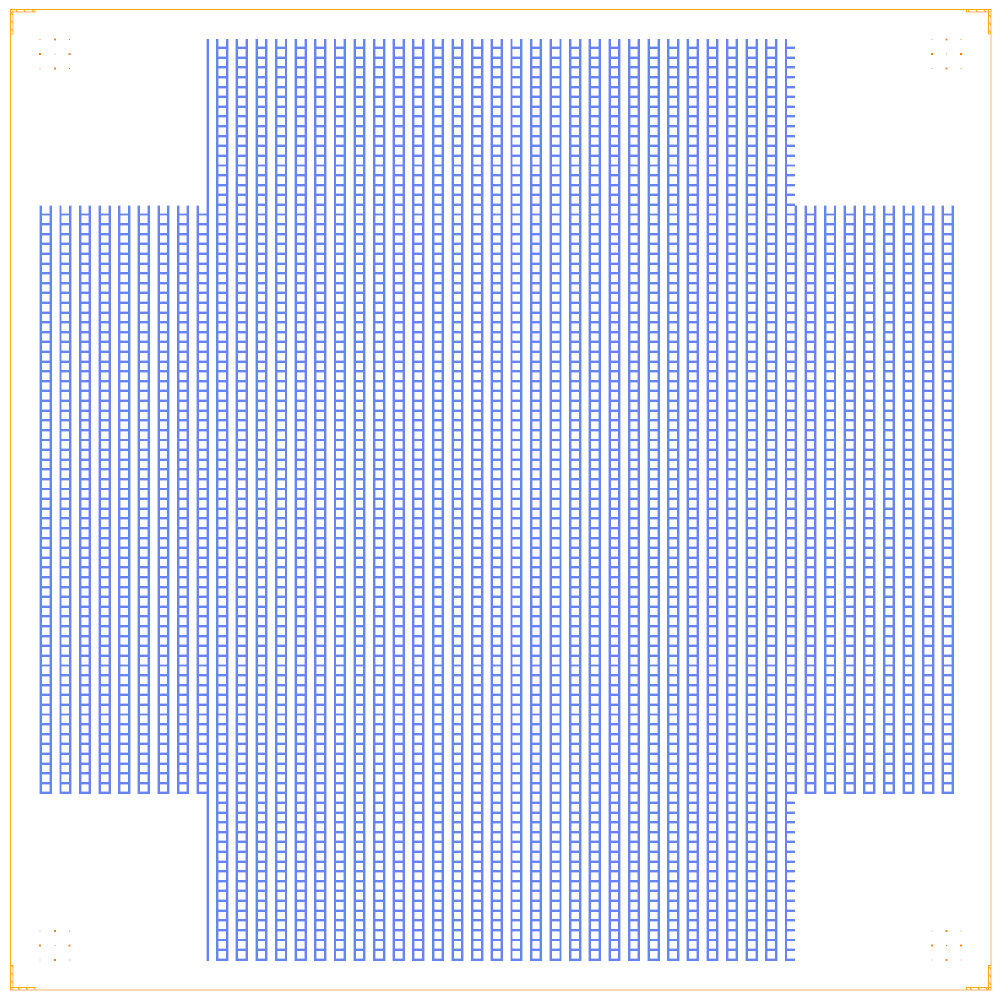

In [4]:
d = Designer("stripes", box=(0, 0, 10000, 10000), chip={"name_chip": "CTest", "cheese": "original"}, live=LIVE)
# No cheese here: the process-test patterns need none. The PDK band (kept for the PDK, not used) is the same call with
# "cheese": "pdk"; it would put 5 µm holes round the 3/0 keep-out and none on the test patterns:
# d = Designer("stripes", box=(0, 0, 10000, 10000), chip={"name_chip": "CTest", "cheese": "pdk"}, live=LIVE)
d.add("CHIP", "Stripes", at=(0, 0), frames_enabled=[])   # KQC chip PCell, no KQC frame
print("centring shift (µm):", center_in_die(d))
rebuild(d)
DESIGN = d.save(OUT / "stripes.json")
print(d, "→", DESIGN)
snap(d, STEPS / "1_chip.png", box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420);

## 4 · Pads and the pad rule

**PDK rule:** a bond pad's or launcher's outer etch edge sits `frame.pad_edge` (100 µm) from the die edge
(`edge="auto"` on a pad instance). This chip has no pad instances and no launchers (the table below is empty): any probe pads belong to KQC's drawing of the cell, so the rule has nothing to place.

In [5]:
display(Markdown(pads_md(d)))

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| – | no bond pads or launchers | – | – | – |

## 5 · Components

The one component is the chip cell itself (placed in step 3).

## 6 · Routes

None: there are no RF lines on this chip.

## 7 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to read. **PDK
design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): flagged,
never enforced — the rebuild keeps the source's choices. `pdk_report` adds the cheese source, the centring
and the junction types.

**Here:** 0 errors and 4 `frame_keepout` warnings: the chip cell's bounding box spans the 10 × 10 mm chip and so overlaps the four corner marker areas; nothing the cell draws sits on the dicing L's or the alignment grids (the frame-corner snapshot shows it). No PDK design warning; `pdk_report` gives no cheese ("the original design's own (or none)"), the content 40 µm off in x and no junctions.

In [6]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

**0 errors · 4 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `frame_keepout` | 4 | CHIP overlaps the marker_area_sw |

| check | value |
|---|---|
| cheese | the original design's own (or none) |
| content centre − die centre | (-40, +0) µm |
| junction types | — |
| PDK design warnings | 0 (none) |

## 8 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit from the components' LOM models. No component here has one (the
chip is a process test structure), so the netlist is ground only.

In [7]:
lb = d.lom()
show_netlist(lb)
print(lom_summary(lb))

**1 nodes · 0 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |

| branch | type | nodes | estimate |
|---|---|---|---|

**Unconnected ports:** none

{'nodes': 0, 'branches': 0, 'controls': 0, 'unconnected': 0}


## 9 · LOM simulation — not applicable

There are no junctions, qubits or resonators, so there is nothing to simulate. The chip is measured in the process
(optical / EBL inspection, DC probing), not with microwaves.

## 10 · FEM: send the jobs

One job per sim group and analysis: the group is cut out of the chip with its margin, every line leaving the
box ends in a port, junctions are lumped ports, and the ground grid is removed (simulation exports never have
cheese). The table lists each job's ports and C-matrix nets (named after islands, couplers and routes, so the
result maps back onto the LOM nodes).

With `RUN_FEM = True` and AEDT 2024 R1 (or later) installed, `send_fem_jobs` solves each Ansys job in a **new
batch, non-graphical** AEDT (`solve_job`) — an AEDT window you have open is never touched. The command-line
equivalent is `qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

Here: nothing to export: the chip has no sim groups (a process structure has nothing for a C-matrix or
eigenmode solve), so `send_fem_jobs` writes no job.

In [8]:
jobs = send_fem_jobs(DESIGN, run=RUN_FEM)
display(Markdown(jobs_md(jobs) if jobs else "No sim groups: no FEM job."))

0 job(s) exported; RUN_FEM is False, nothing solved.


No sim groups: no FEM job.

## 11 · Bring the results back

When a job has been solved its folder holds `results/results.json`. `fem_back` then calls
`fill(model, design, job)`: the C-matrix (or eigenmode) values replace the component estimates branch by
branch (matched by net name), and the table compares the two. `simulate(filled)` re-runs the LOM on the
extracted values. Until then the cell says which jobs are still waiting.

In [9]:
filled, md = fem_back(lb.model, DESIGN, jobs)
display(Markdown(md or "No FEM jobs."))
if filled:
    from quantcore_circuits.lom.simulate import simulate
    key, fc = next(iter(filled.items()))
    display(Markdown(f"**LOM on the FEM values ({key}):**\n\n" + modes_md(simulate(fc, max_modes=2))))

No FEM jobs.

## 12 · Change one property — not applicable

`Stripes` is a fixed test pattern and there is no simulation to re-run, so this step has nothing to change and
re-simulate. A variant would be a new KQC parameter set for the cell, checked in the fab view.

## 13 · Build and export

**The design file.** `stripes.json` (saved in step 3) is the whole design: `qcc build
examples/designs/kqc/test_chips/stripes.json` rebuilds `build/stripes.oas` + its sidecar, and the KLayout plugin,
`qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the filled 3/0 keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese
hole), no junction layers,
and the frame (100/0, 1000/0, 1001/0). In this run: 1/0 47 polygons, 3/0 1; cheese source `original`, 0 holes. Corner rounding (fab only) is skipped unless `FULL_FAB`;
`qcc mask examples/designs/kqc/test_chips/stripes.json` writes the complete file.

In [10]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 47 |
| 3/0 | M3 | 1 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `original`, 0 holes on the mask.

→ `build/stripes_fab.oas`

## 14 · Snapshots

The full chip; the die frame's south-west corner (dicing L on 1000/0,
3 × 3 alignment grid on 1001/0); and the chip centre in the **fab view** (the mask from step 13). The chip
boundary 100/0 is drawn as an outline.

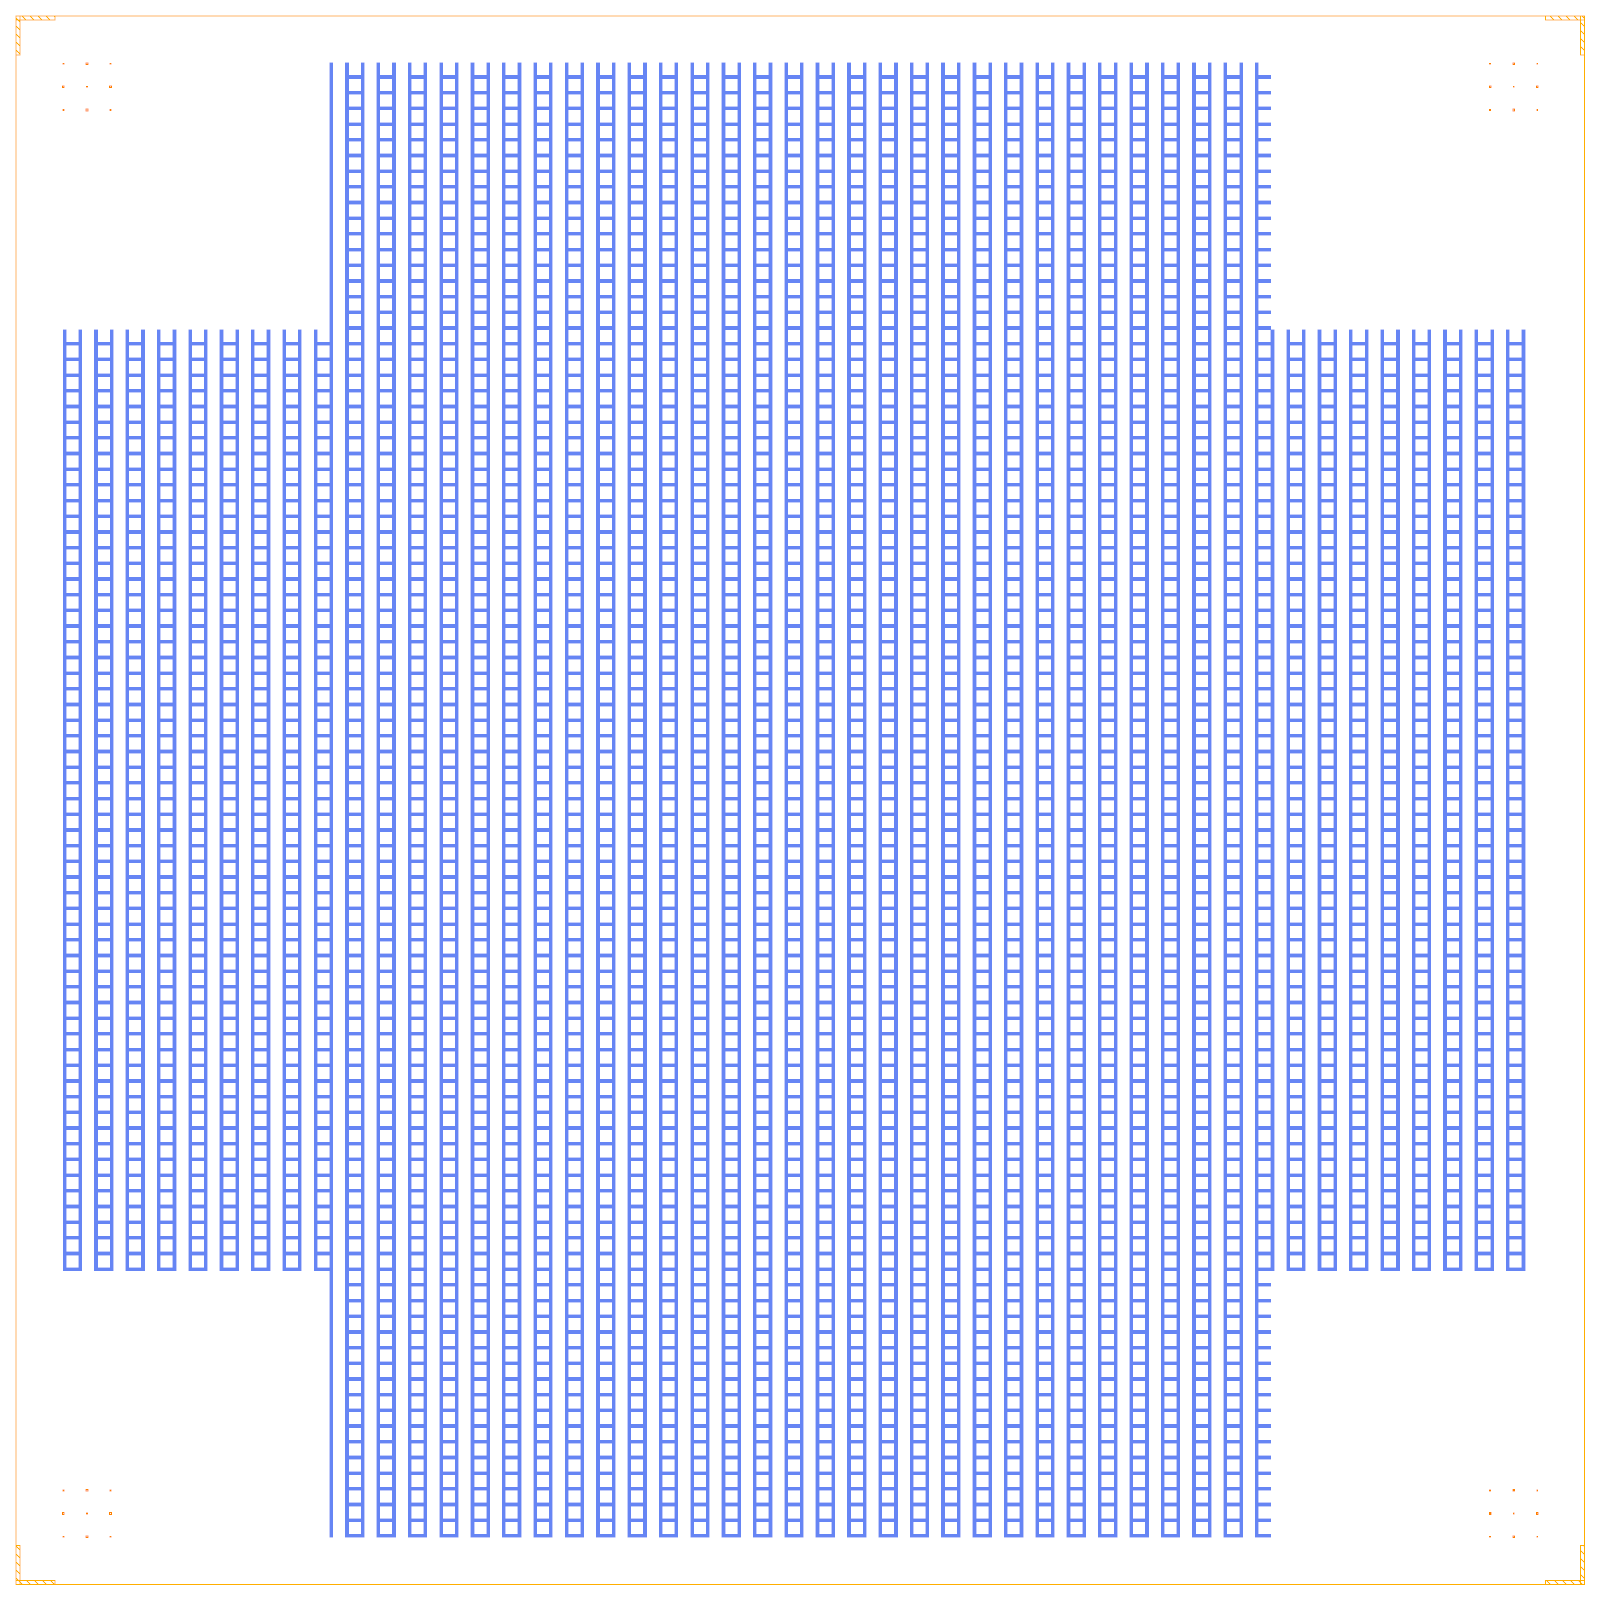

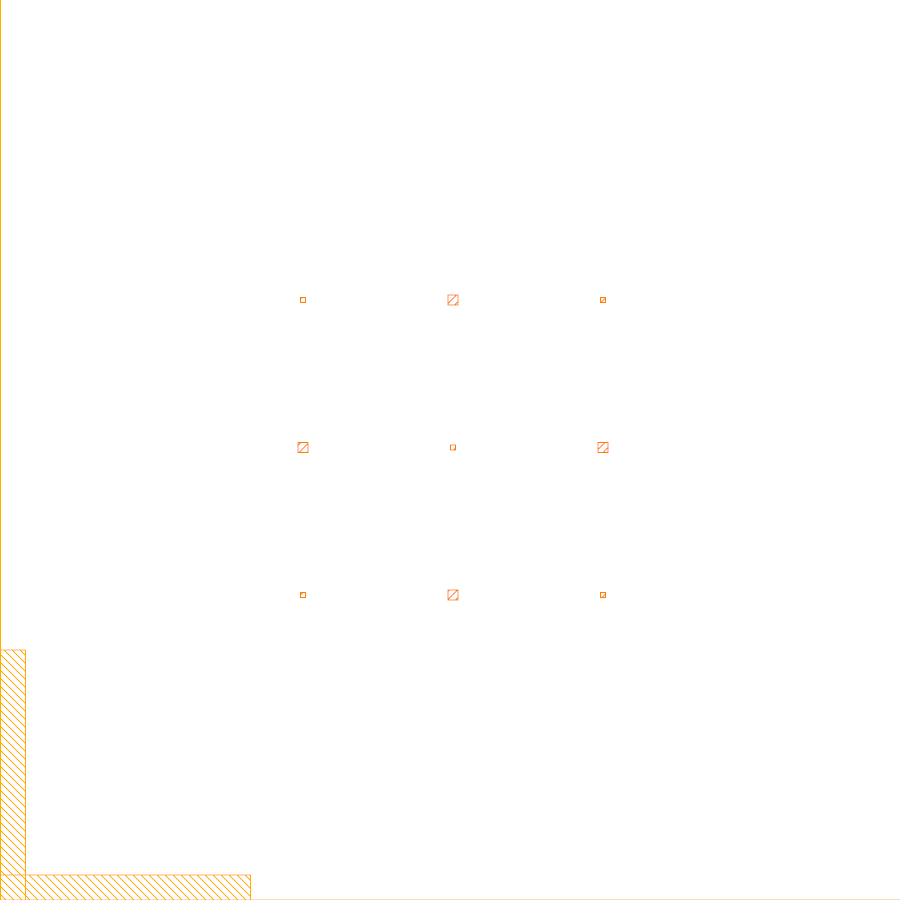

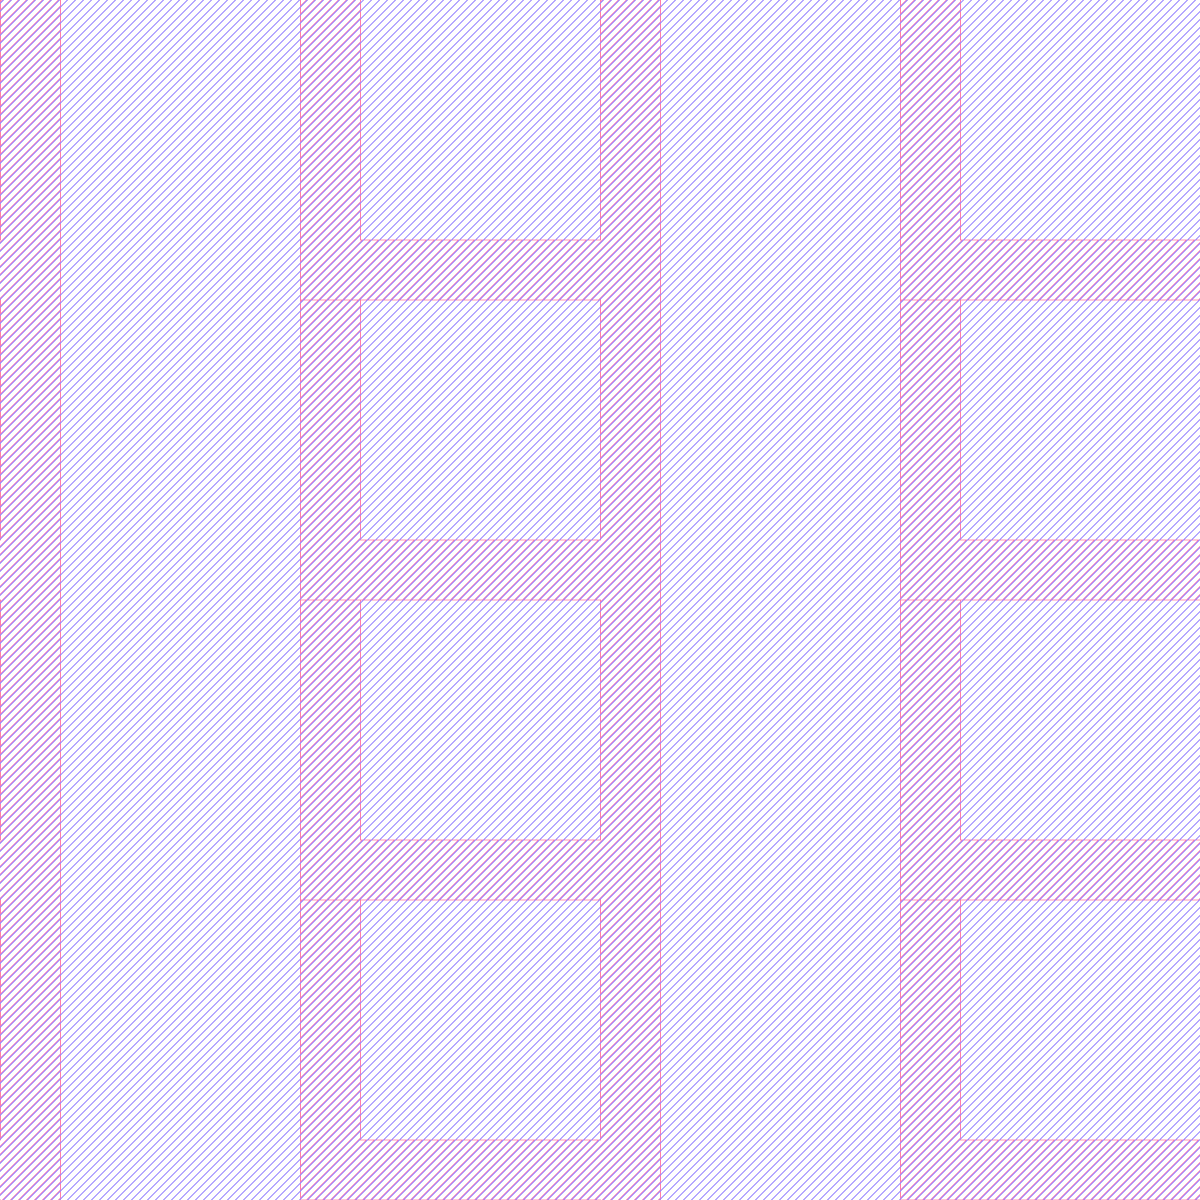

In [11]:
X0, Y0 = d.data["instances"]["CHIP"]["place"]["at"]   # the cell's origin (after the centring shift)
show_snapshot(d, OUT / "stripes.png", box=(-100, -100, 10100, 10100))
show_snapshot(d, OUT / "stripes_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300)
snap_file(Path("build") / "stripes_fab.oas", OUT / "stripes_fab.png", box=(X0 + 4800, Y0 + 4800, X0 + 5200, Y0 + 5200), size=(1200, 1200), width=420);

**Reference: XOR with the source.** KQC's `Stripes` built stand-alone (with KQC's own frame), XOR-ed layer by layer
with this build (`refpoints` and the `instance_names` label layer are annotation and are skipped). **The rebuild is
expected to differ** by design in the frame (KQC's ChipFrame vs the Quantcore die frame) and the ground grid (KQC's stand-alone build has none). A
reference, not a pass/fail check.

| layer | XOR area (µm²) |
|---|---|
| 1t1_base_metal_gap_wo_grid (130/1) | 8.63e+06 |
| 1t1_base_metal_gap_for_EBL (134/1) | 8.63e+06 |
| 1t1_ground_grid_avoidance (133/1) | 1.53e+07 |
| 1t1_chip_dicing (158/1) | 2.68e+05 |
| 1t1_airbridge_pads (146/1) | 5.4e+05 |
| 1t1_airbridge_flyover (147/1) | 2.81e+05 |

**Total XOR area: 3.36e+07 µm²**

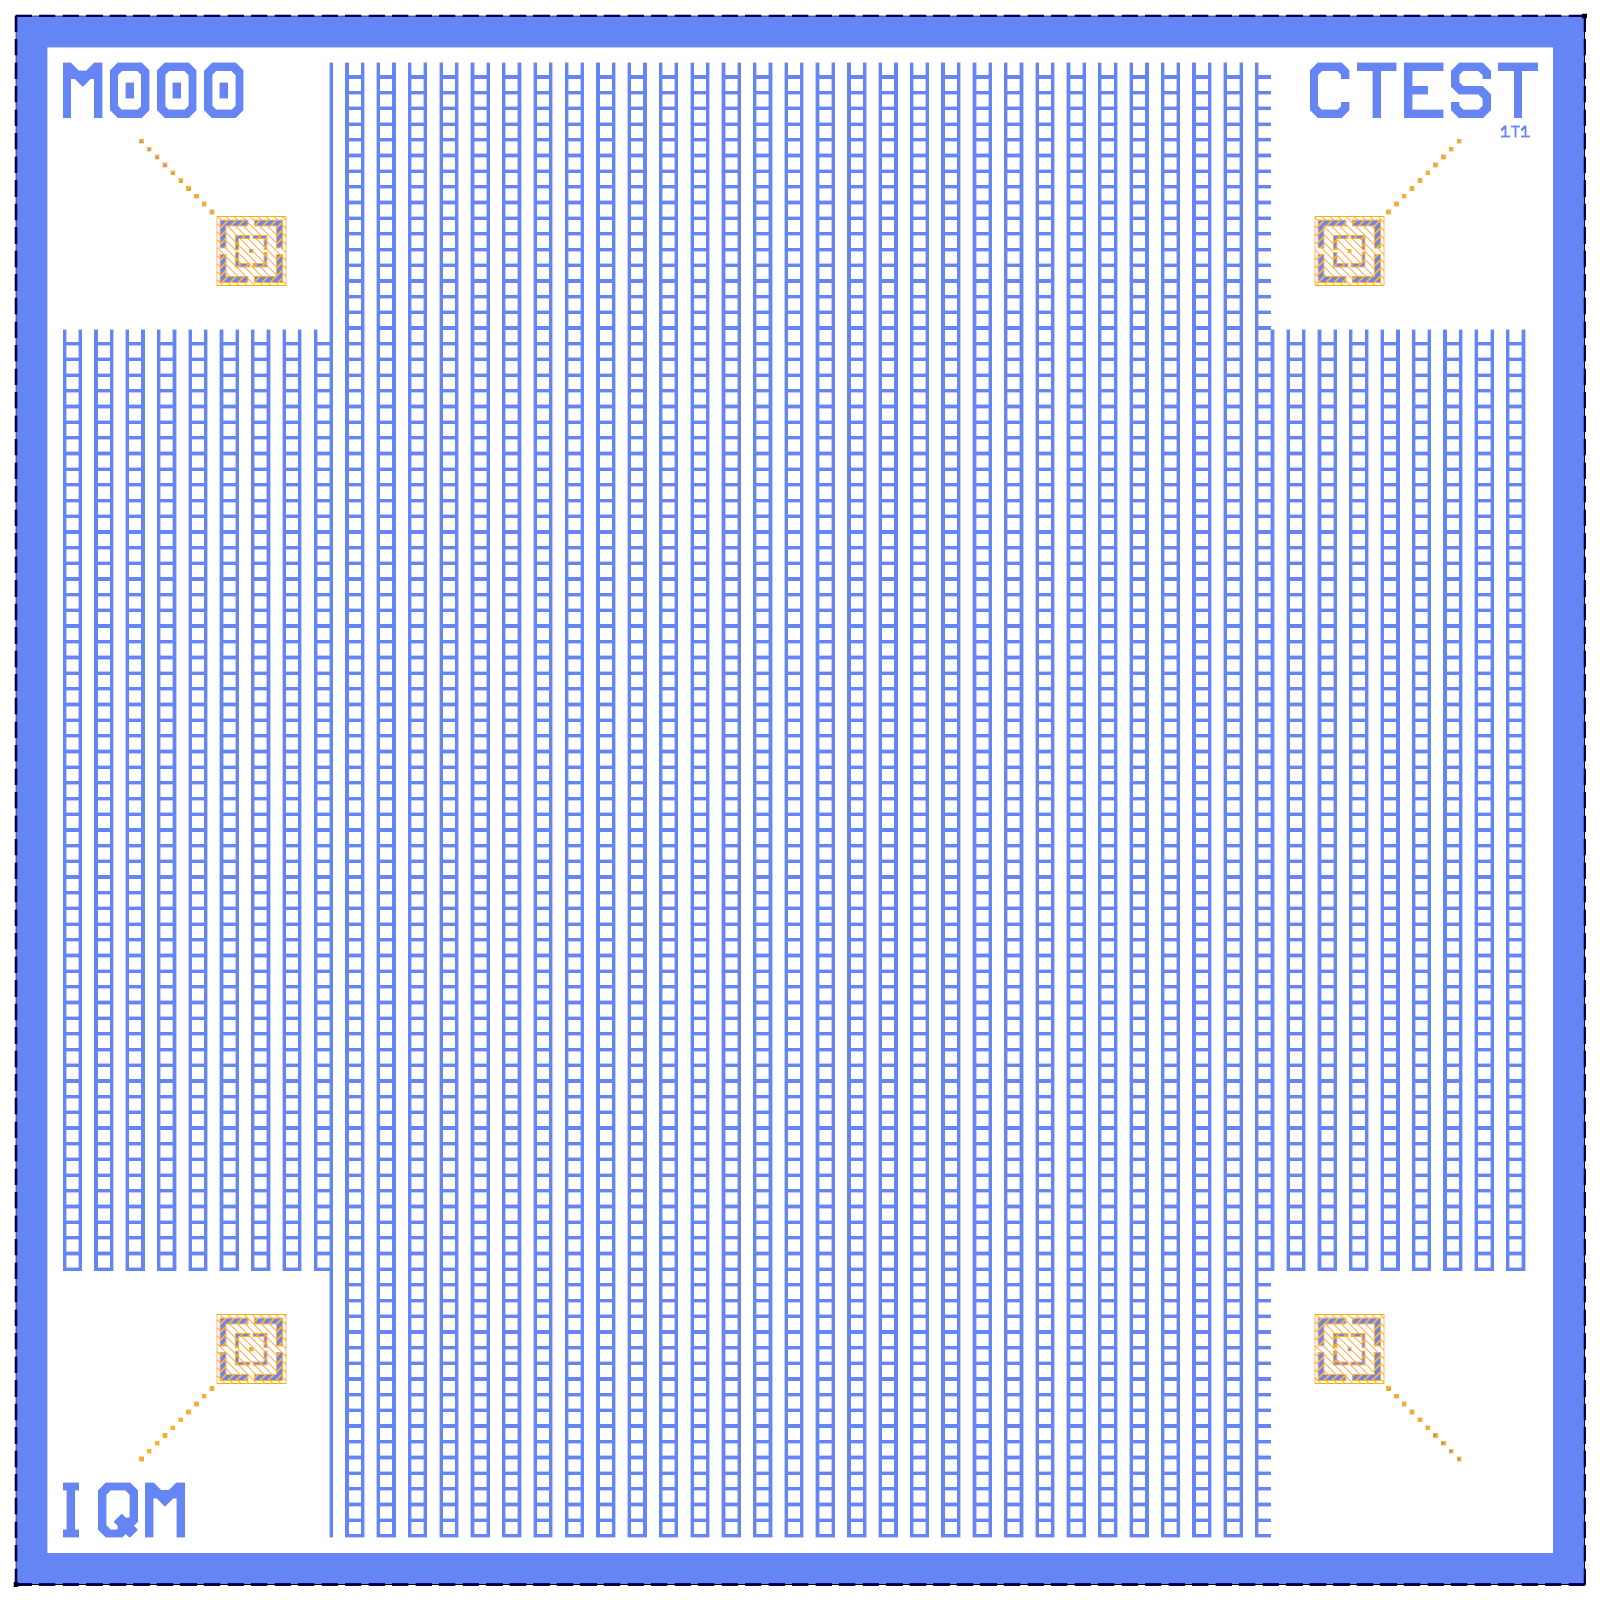

In [12]:
import klayout.db as kdb
from kqcircuits.chips.stripes import Stripes
from kqcircuits.pya_resolver import pya

ref = pya.Layout()
ref_top = ref.create_cell("ref")
ref_top.insert(pya.DCellInstArray(Stripes.create(ref).cell_index(), pya.DTrans()))
ref.write(str(Path("build") / "stripes_kqc_original.oas"))
ly = kdb.Layout()
ly.read(str(d.out))
top = ly.top_cell()
by_name = {ly.get_info(i).name: i for i in ly.layer_indexes()}
rows, total = ["| layer | XOR area (µm²) |", "|---|---|"], 0.0
for li in ref.layer_indexes():
    info = ref.get_info(li)
    a = kdb.Region(ref_top.begin_shapes_rec(li)).merged()
    if a.is_empty() or info.name in ("refpoints", "instance_names"):
        continue
    b = kdb.Region(top.begin_shapes_rec(by_name[info.name])).merged() if info.name in by_name else kdb.Region()
    x = (a ^ b).area() * ref.dbu ** 2
    total += x
    rows.append(f"| {info.name} ({info.layer}/{info.datatype}) | {x:.3g} |")
display(Markdown("\n".join(rows) + f"\n\n**Total XOR area: {total:.3g} µm²**"))
snap_file(Path("build") / "stripes_kqc_original.oas", OUT / "stripes_kqc.png", box=(-100, -100, 10100, 10100), width=420);

**Here:** the XOR (3.4 × 10⁷ µm²) is all in KQC's frame: the base etch and EBL layers (8.6 × 10⁶ µm² each: KQC's dicing edge and markers), the avoidance, dicing and airbridge-marker layers. The base-etch XOR is the same 8.63 × 10⁶ µm² on Empty, Stripes and JunctionTest, so the stripe pattern agrees.

## 15 · Summary

| | |
|---|---|
| **matches the source** | the whole `Stripes` cell (KQC's own `build()`) |
| **differs (PDK)** | the Quantcore die frame instead of KQC's ChipFrame; the PDK fab layer map; no cheese, as in the source |
| **not applicable** | the pad rule (no pad instances), routes, LOM, the iterate step, FEM |
| **PDK design warnings** | as listed in step 7 |
| **FEM** | no sim groups, no jobs |